# 04 – Finding 2: are applicants with no existing loans always rejected?
**Test:** change **only** `existing_loans` (0 to 8) for every applicant, keeping everything else the same.
**Expected if the model is sensible:** more loans → more risk. Zero loans should be the *safest*.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from common import BLUE, ORANGE, finish_chart, load_data, sweep, what_if

df = load_data()

## 1. All 600 applicants

In [2]:
everyone = sweep(df, "existing_loans", range(0, 9), probe_file="04_existing_loans_sweep.csv")
everyone

,existing_loans,reject_rate,avg_risk
0,0,1.000,1.000
1,1,0.435,0.429
2,2,0.473,0.475
3,3,0.532,0.530
4,4,0.572,0.570
5,5,0.617,0.617
6,6,0.662,0.662
7,7,0.727,0.729
8,8,0.788,0.786


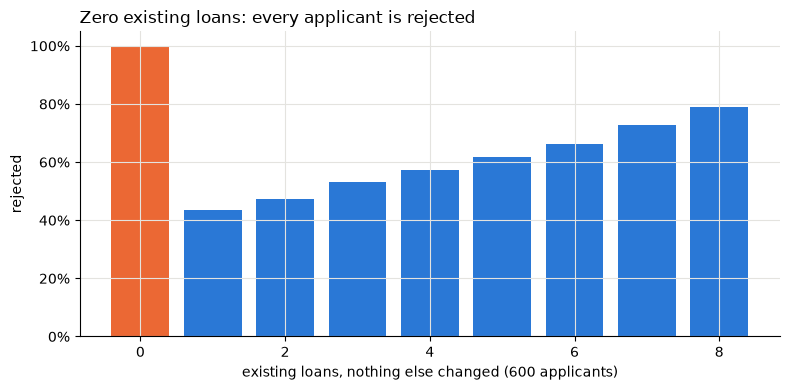

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(everyone.existing_loans, everyone.reject_rate, color=[ORANGE] + [BLUE] * 8)
ax.set_xlabel("existing loans, nothing else changed (600 applicants)")
finish_chart(ax, "Zero existing loans: every applicant is rejected", "fig2_existing_loans.png")

## 2. People approved with 1 loan: what happens at 0?

In [4]:
_, rejected = what_if(df, existing_loans=1)
approved = df[~rejected]
_, rejected_at_0 = what_if(approved, existing_loans=0)
print(f"Approved with 1 loan: {len(approved)}.  Rejected when set to 0 loans: {rejected_at_0.sum()}")

Approved with 1 loan: 339.  Rejected when set to 0 loans: 339


## 3. Even very strong applicants?
Credit score ≥ 780, income ₹60k–2L, loan at most 6× monthly income.

In [5]:
strong = df[(df.credit_score >= 780) & df.monthly_income.between(60000, 200000)
            & (df.loan_amount <= 6 * df.monthly_income)]
table = sweep(strong, "existing_loans", range(0, 9))
print(len(strong), "strong applicants")
table

14 strong applicants


,existing_loans,reject_rate,avg_risk
0,0,1.000,1.000
1,1,0.000,0.004
2,2,0.000,0.003
3,3,0.000,0.004
4,4,0.000,0.004
5,5,0.000,0.005
6,6,0.000,0.014
7,7,0.143,0.140
8,8,0.214,0.215


## 4. Idea to rule out: "zero loans means no credit history"
If zero-loan applicants had no credit history, their credit scores would look different.

In [6]:
df.groupby(df.existing_loans == 0).credit_score.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
existing_loans,,,,,,,,
False,492.0,713.0,69.0,485.0,669.0,715.0,762.0,900.0
True,108.0,715.0,77.0,514.0,659.0,722.0,766.0,900.0


Their credit scores are the same as everyone else's (median 722 vs 715), so this idea is **false**.

**Conclusion:** zero existing loans switches the model to "reject" for everyone. A strong applicant
with 8 loans is more likely to be approved than the same person with none.